# Vẽ hiện tượng quá khớp (mục 3.2.1): hồi quy đa thức bậc 1, bậc 10 và bậc 10 có điều chuẩn Ridge

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_error

IMAGES = Path('.')   # thư mục images/ (notebook chạy trong images/)
DATA = Path('..') / 'data'   # thư mục data/

df = pd.read_csv(DATA / "house_prices.csv")
X = df[["area"]].values                              # chỉ dùng đặc trưng diện tích
y = df["price"].values
X_pool, X_test, y_pool, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

Tập huấn luyện nhỏ: chỉ lấy 20 căn trong tập train, không giao với test

In [2]:
train_idx = np.random.RandomState(0).choice(len(X_pool), 20, replace=False)
X_train, y_train = X_pool[train_idx], y_pool[train_idx]

(tên, mô hình, bậc đa thức, màu, kiểu nét)

Bậc 1 368.9321524741412 555.220428302967
Bậc 10 309.37217452357476 943.7290903164079
Bậc 10 + Ridge 378.8066110461134 596.4343387071223


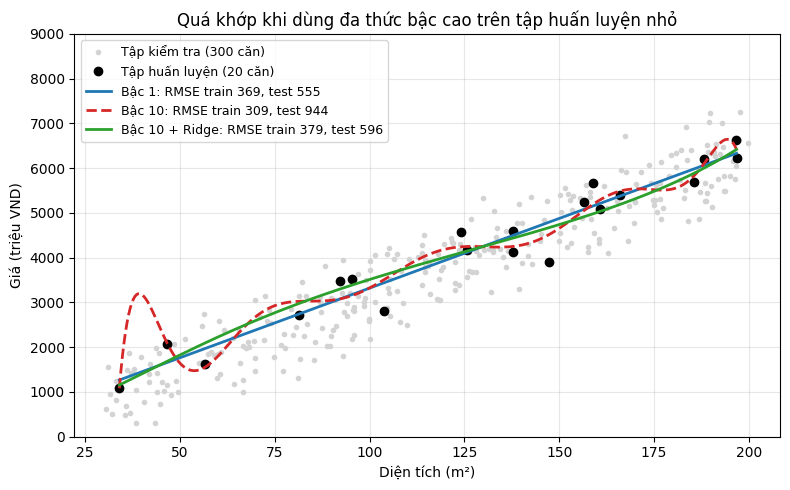

In [3]:
models = [
    ("Bậc 1", LinearRegression(), 1, "#1F77B4", "-"),
    ("Bậc 10", LinearRegression(), 10, "#D62728", "--"),
    ("Bậc 10 + Ridge", Ridge(alpha=1.0), 10, "#2CA02C", "-"),
]

x_line = np.linspace(X_train.min(), X_train.max(), 400).reshape(-1, 1)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(X_test[:300], y_test[:300], '.', color="lightgray", label="Tập kiểm tra (300 căn)")
ax.plot(X_train, y_train, 'ko', label="Tập huấn luyện (20 căn)")
for name, model, degree, color, style in models:
    # Chuẩn hóa trước khi lũy thừa: nếu lũy thừa diện tích gốc (200^10 ~ 1e23) thì các cột gần như trùng nhau,
    # nghiệm bậc 10 không ổn định và thay đổi theo phiên bản thư viện
    pipeline = make_pipeline(StandardScaler(), PolynomialFeatures(degree, include_bias=False),
                             StandardScaler(), model)
    pipeline.fit(X_train, y_train)
    rmse_train = np.sqrt(mean_squared_error(y_train, pipeline.predict(X_train)))
    rmse_test = np.sqrt(mean_squared_error(y_test, pipeline.predict(X_test)))
    ax.plot(x_line, pipeline.predict(x_line), color=color, ls=style, lw=2,
            label=f"{name}: RMSE train {rmse_train:.0f}, test {rmse_test:.0f}")
    print(name, rmse_train, rmse_test)

ax.set_ylim(0, 9000)
ax.set_xlabel("Diện tích (m²)"); ax.set_ylabel("Giá (triệu VND)")
ax.set_title("Quá khớp khi dùng đa thức bậc cao trên tập huấn luyện nhỏ")
ax.legend(loc="upper left", fontsize=9); ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(IMAGES / "overfitting.png", dpi=150)